# 🌿 Nhận Dạng Bệnh Lá Cà Chua — Tomato Disease Classification

**Dataset**: PlantVillage (chỉ giữ 10 class Tomato)  
**Models**: EfficientNet-B0 và ResNet50 (Transfer Learning)  
**Framework**: PyTorch

---

### 📌 Pipeline tổng quan

| Bước | Nội dung |
|------|----------|
| 1 | 🔧 Import thư viện & Seed reproducibility |
| 2 | ⚙️ Cấu hình hyperparameters & đường dẫn |
| 3 | 📦 Data Preprocessing (Transforms, Dataset, Stratified Split) |
| 4 | 📊 Khám phá dữ liệu (Class distribution, Sample images) |
| 5 | 🏗️ Định nghĩa Model (EfficientNet-B0, ResNet50) |
| 6 | 🚀 Training (Early Stopping, LR Scheduler) |
| 7 | 📈 Đánh giá (Accuracy, Classification Report, Confusion Matrix) |
| 8 | 🏆 So sánh 2 model |

## 1. 🔧 Import Thư Viện & Thiết Lập Seed

In [2]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, datasets, models

import warnings
warnings.filterwarnings("ignore")

# ── Thiết lập seed để tái tạo kết quả ───────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

print(f"PyTorch version : {torch.__version__}")
print(f"GPU available   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU name        : {torch.cuda.get_device_name(0)}")
else:
    print("Không có GPU — training sẽ chậm hơn")

PyTorch version : 2.10.0+cu128
GPU available   : True
GPU name        : Tesla T4


## 2. ⚙️ Cấu Hình Hyperparameters & Đường Dẫn

In [3]:
import os

# ════════════════════════════════════════════════════════════════
#   ⚙️  CẤU HÌNH — chỉnh sửa ở đây nếu cần
# ════════════════════════════════════════════════════════════════

# ── Đường dẫn dataset ────────────────────────────────────────────
# Kaggle dataset: vthanhdt/plantvillagetomato
# Cấu trúc thư mục trên Kaggle sau khi upload:
#   /kaggle/input/datasets/vthanhdt/plantvillagetomato/
#       ├── Tomato_Bacterial_spot/
#       ├── Tomato_Early_blight/
#       └── ...  (nếu class folders nằm thẳng ở root)
#   HOẶC:
#       └── PlantVillage/
#               ├── Tomato_Bacterial_spot/
#               └── ...  (nếu có subfolder PlantVillage)

KAGGLE_ROOT = "/kaggle/input/datasets/vthanhdt/plantvillagetomato"

# Tự động phát hiện cấu trúc thư mục
if os.path.isdir(os.path.join(KAGGLE_ROOT, "PlantVillage")):
    DATA_DIR = os.path.join(KAGGLE_ROOT, "PlantVillage")
else:
    DATA_DIR = KAGGLE_ROOT

BATCH_SIZE  = 32          # Số ảnh mỗi batch
NUM_EPOCHS  = 30          # Số epoch tối đa
LR          = 1e-3        # Learning rate ban đầu
PATIENCE    = 5           # Số epoch không cải thiện trước khi dừng
IMG_SIZE    = 224         # Kích thước ảnh đầu vào
DROPOUT     = 0.5         # Dropout rate cho lớp đầu (lớp sau dùng DROPOUT/2)
NUM_WORKERS = 2           # Kaggle (Linux): có thể dùng > 0
DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# ════════════════════════════════════════════════════════════════

print(f"Device      : {DEVICE}")
print(f"Data dir    : {DATA_DIR}")
print(f"Dir exists  : {os.path.isdir(DATA_DIR)}")
print(f"Batch size  : {BATCH_SIZE}")
print(f"Max epochs  : {NUM_EPOCHS}")
print(f"LR          : {LR}")
print(f"Patience    : {PATIENCE}")
print(f"Dropout     : {DROPOUT} / {DROPOUT/2}")
print(f"Num workers : {NUM_WORKERS}")
print(f"Image size  : {IMG_SIZE}x{IMG_SIZE}")

Device      : cuda
Data dir    : /kaggle/input/datasets/vthanhdt/plantvillagetomato
Dir exists  : True
Batch size  : 32
Max epochs  : 30
LR          : 0.001
Patience    : 5
Dropout     : 0.5 / 0.25
Num workers : 2
Image size  : 224x224


## 3. 📦 Data Preprocessing

### 3.1 Data Transforms (Augmentation)

> **Lưu ý**: Augmentation chỉ áp dụng cho **tập Train**.  
> Val và Test chỉ resize + normalize để đánh giá chính xác.

In [5]:
data_transforms = {
    # ── Train: augmentation mạnh để tăng tính tổng quát ─────────
    'train': transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.RandomRotation(15),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    # ── Val / Test: KHÔNG augment ────────────────────────────────
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}
print("✅ Data transforms defined")

✅ Data transforms defined


### 3.2 Custom Dataset Class

Dataset tùy chỉnh cho phép:
- Bỏ qua ảnh bị hỏng tự động (không crash)
- Nhận danh sách `(path, label)` bất kỳ (train/val/test)

In [7]:
class CustomImageDataset(Dataset):
    """Dataset tùy chỉnh — tự động bỏ qua ảnh bị lỗi."""

    def __init__(self, samples, transform=None):
        self.samples   = samples    # list of (path, label_idx)
        self.transform = transform

    def __getitem__(self, index):
        path, label = self.samples[index]
        try:
            image = Image.open(path).convert("RGB")
        except (IOError, UnidentifiedImageError):
            # Ảnh bị hỏng → thử ảnh tiếp theo
            return self.__getitem__((index + 1) % len(self.samples))
        if self.transform:
            image = self.transform(image)
        return image, label

    def __len__(self):
        return len(self.samples)

print("✅ CustomImageDataset defined")

✅ CustomImageDataset defined


### 3.3 Load Dataset & Stratified Split

**Vì sao dùng Stratified Split?**  
Đảm bảo tỉ lệ mỗi class trong train/val/test **đồng đều nhau**,  
tránh tình trạng val/test bị thiếu class hoặc lệch phân phối.

**Tỉ lệ**: Train 70% / Validation 15% / Test 15%

In [8]:
# ── Load toàn bộ metadata từ thư mục ────────────────────────────────
full_dataset = datasets.ImageFolder(root=DATA_DIR, transform=None)
all_samples  = full_dataset.samples    # list of (path, class_idx)
classes      = full_dataset.classes    # list of class names
num_classes  = len(classes)

print(f"📂 Số class   : {num_classes}")
print(f"📸 Tổng ảnh   : {len(all_samples)}")
print("\nDanh sách class:")
for i, cls in enumerate(classes):
    count = sum(1 for _, l in all_samples if l == i)
    print(f"  [{i:2d}] {cls:<55s} → {count:4d} ảnh")

# ── Tách paths và labels để dùng sklearn ────────────────────────────
paths  = [s[0] for s in all_samples]
labels = [s[1] for s in all_samples]

# ── Stratified Split ─────────────────────────────────────────────────
# Bước 1: 70% train | 30% còn lại
train_p, temp_p, train_l, temp_l = train_test_split(
    paths, labels, test_size=0.30, random_state=SEED, stratify=labels
)
# Bước 2: 30% còn lại → 50/50 = 15% val | 15% test
val_p, test_p, val_l, test_l = train_test_split(
    temp_p, temp_l, test_size=0.50, random_state=SEED, stratify=temp_l
)

train_samples = list(zip(train_p, train_l))
val_samples   = list(zip(val_p,   val_l))
test_samples  = list(zip(test_p,  test_l))

total = len(all_samples)
print(f"\n✅ Train : {len(train_samples):5d} ảnh  ({len(train_samples)/total*100:.1f}%)")
print(f"✅ Val   : {len(val_samples):5d} ảnh  ({len(val_samples)/total*100:.1f}%)")
print(f"✅ Test  : {len(test_samples):5d} ảnh  ({len(test_samples)/total*100:.1f}%)")

📂 Số class   : 10
📸 Tổng ảnh   : 16011

Danh sách class:
  [ 0] Tomato_Bacterial_spot                                   → 2127 ảnh
  [ 1] Tomato_Early_blight                                     → 1000 ảnh
  [ 2] Tomato_Late_blight                                      → 1909 ảnh
  [ 3] Tomato_Leaf_Mold                                        →  952 ảnh
  [ 4] Tomato_Septoria_leaf_spot                               → 1771 ảnh
  [ 5] Tomato_Spider_mites_Two_spotted_spider_mite             → 1676 ảnh
  [ 6] Tomato__Target_Spot                                     → 1404 ảnh
  [ 7] Tomato__Tomato_YellowLeaf__Curl_Virus                   → 3208 ảnh
  [ 8] Tomato__Tomato_mosaic_virus                             →  373 ảnh
  [ 9] Tomato_healthy                                          → 1591 ảnh

✅ Train : 11207 ảnh  (70.0%)
✅ Val   :  2402 ảnh  (15.0%)
✅ Test  :  2402 ảnh  (15.0%)


### 3.4 Tạo DataLoaders

In [10]:
train_dataset = CustomImageDataset(train_samples, transform=data_transforms['train'])
val_dataset   = CustomImageDataset(val_samples,   transform=data_transforms['val'])
test_dataset  = CustomImageDataset(test_samples,  transform=data_transforms['test'])

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda')
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda')
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda')
)

print("✅ DataLoaders created")
print(f"   Train batches : {len(train_loader)}")
print(f"   Val   batches : {len(val_loader)}")
print(f"   Test  batches : {len(test_loader)}")

✅ DataLoaders created
   Train batches : 351
   Val   batches : 76
   Test  batches : 76


## 4. 📊 Khám Phá Dữ Liệu

### 4.1 Phân Phối Class (Train / Val / Test)

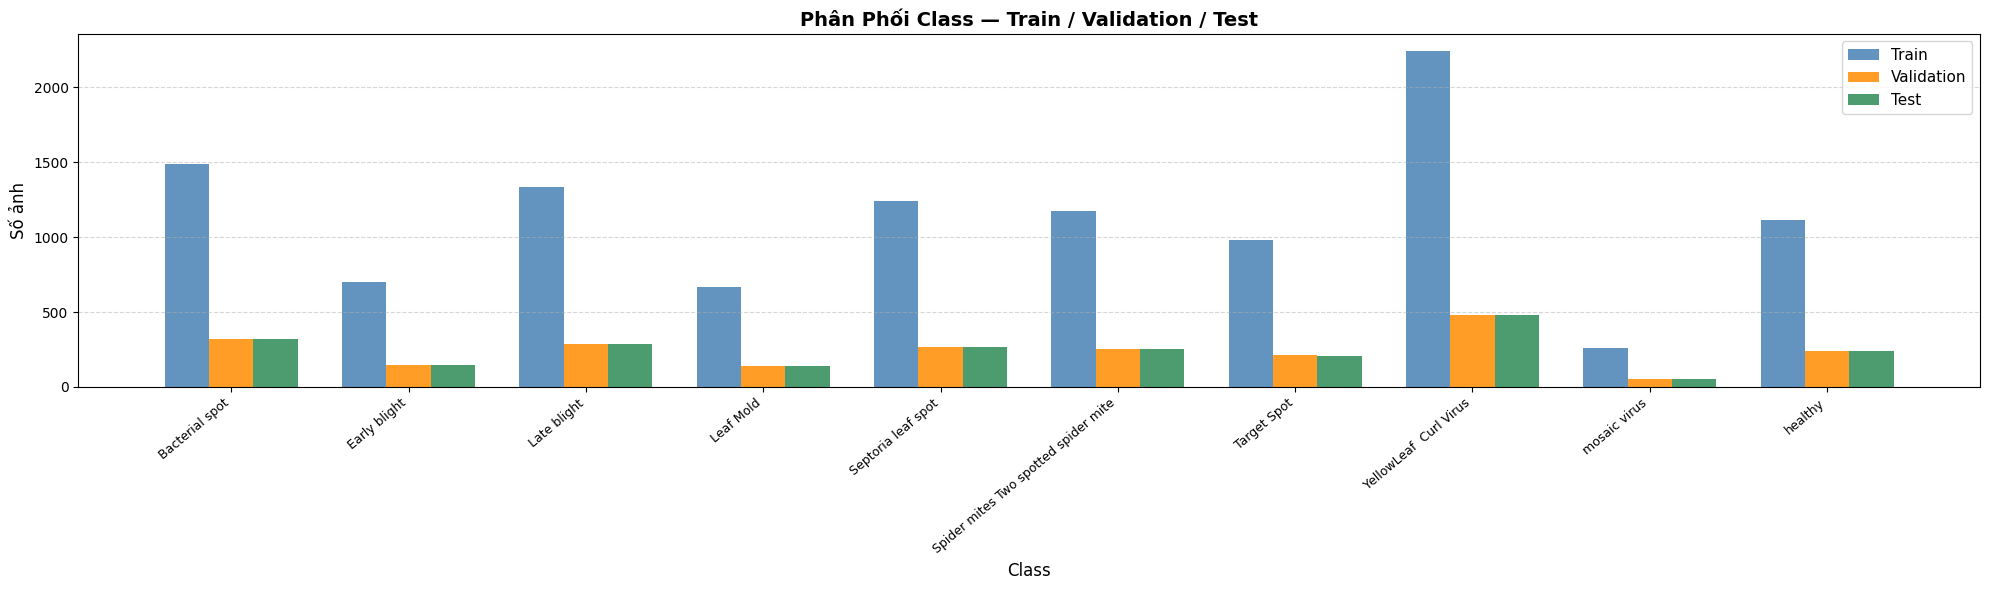


📊 Tổng ảnh mỗi class:
  Tomato_Bacterial_spot                                  : 2127
  Tomato_Early_blight                                    : 1000
  Tomato_Late_blight                                     : 1909
  Tomato_Leaf_Mold                                       :  952
  Tomato_Septoria_leaf_spot                              : 1771
  Tomato_Spider_mites_Two_spotted_spider_mite            : 1676
  Tomato__Target_Spot                                    : 1404
  Tomato__Tomato_YellowLeaf__Curl_Virus                  : 3208
  Tomato__Tomato_mosaic_virus                            :  373
  Tomato_healthy                                         : 1591


In [11]:
train_counter = Counter(train_l)
val_counter   = Counter(val_l)
test_counter  = Counter(test_l)

x     = np.arange(num_classes)
width = 0.25

train_counts = [train_counter.get(i, 0) for i in range(num_classes)]
val_counts   = [val_counter.get(i, 0)   for i in range(num_classes)]
test_counts  = [test_counter.get(i, 0)  for i in range(num_classes)]

# Rút gọn tên class để hiển thị
short_names = [
    c.replace('Tomato__', '').replace('Tomato_', '').replace('_', ' ')
    for c in classes
]

plt.figure(figsize=(20, 6))
plt.bar(x - width, train_counts, width, label='Train',      color='steelblue',  alpha=0.85)
plt.bar(x,         val_counts,   width, label='Validation', color='darkorange', alpha=0.85)
plt.bar(x + width, test_counts,  width, label='Test',       color='seagreen',   alpha=0.85)

plt.xlabel('Class', fontsize=12)
plt.ylabel('Số ảnh', fontsize=12)
plt.title('Phân Phối Class — Train / Validation / Test', fontsize=14, fontweight='bold')
plt.xticks(x, short_names, rotation=40, ha='right', fontsize=9)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("\n📊 Tổng ảnh mỗi class:")
for i, cls in enumerate(classes):
    total_cls = train_counts[i] + val_counts[i] + test_counts[i]
    print(f"  {cls:<55s}: {total_cls:4d}")

### 4.2 Xem Ảnh Mẫu Từ Mỗi Class

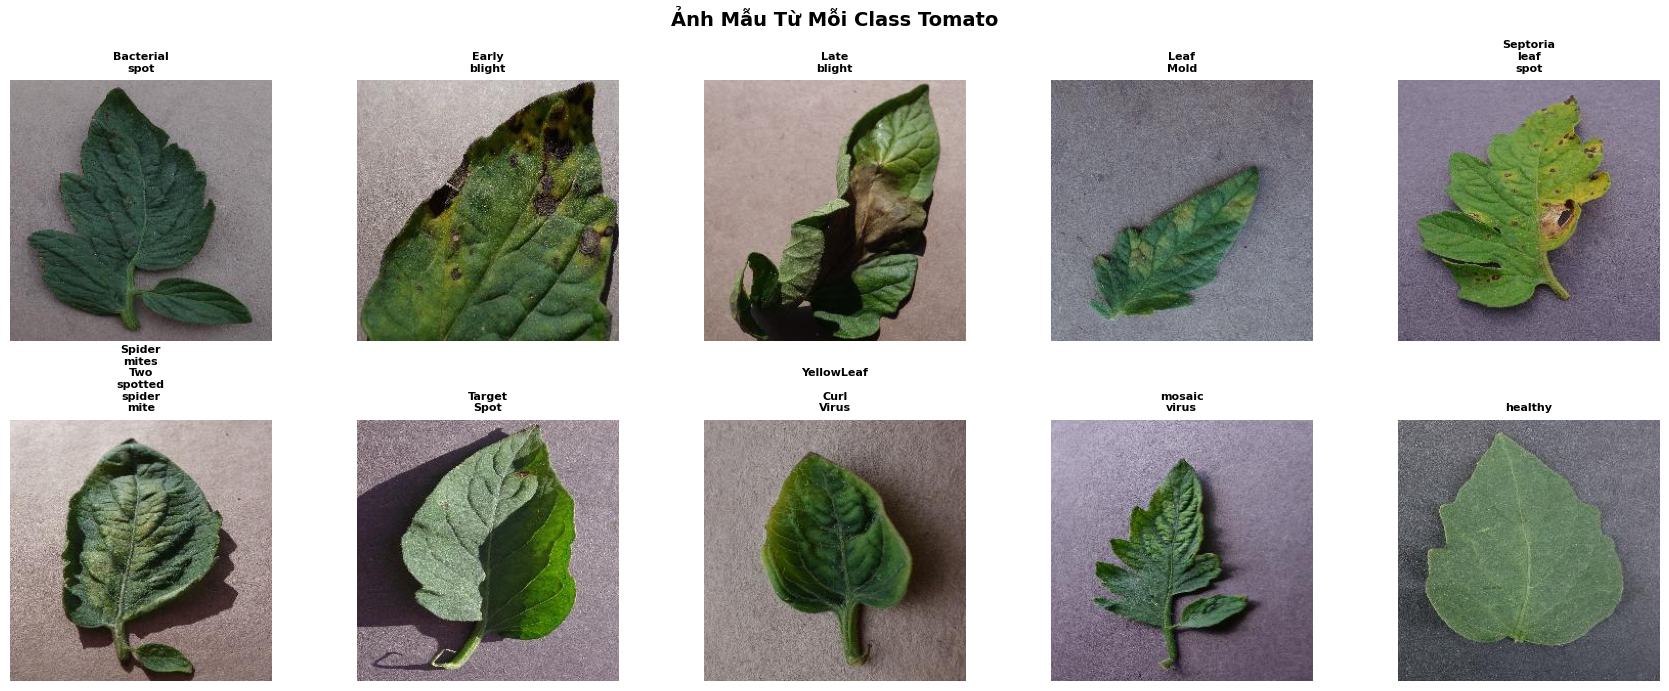

In [12]:
# Lấy 1 ảnh đại diện cho mỗi class
n_cols = 5
n_rows = (num_classes + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3.5, n_rows * 3.5))
axes = axes.flatten()

for cls_idx, cls_name in enumerate(classes):
    cls_samples = [(p, l) for p, l in all_samples if l == cls_idx]
    if not cls_samples:
        axes[cls_idx].axis('off')
        continue
    path, _ = cls_samples[0]
    img = Image.open(path).convert("RGB")
    axes[cls_idx].imshow(img)
    short = cls_name.replace('Tomato__', '').replace('Tomato_', '').replace('_', '\n')
    axes[cls_idx].set_title(short, fontsize=8, fontweight='bold')
    axes[cls_idx].axis('off')

# Ẩn ô thừa
for j in range(num_classes, len(axes)):
    axes[j].axis('off')

plt.suptitle("Ảnh Mẫu Từ Mỗi Class Tomato", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. 🏗️ Định Nghĩa Model (Transfer Learning)

**Chiến lược**: Freeze toàn bộ backbone pretrained (ImageNet),  
chỉ train lại **classifier head** để phân loại bệnh Tomato.

### Kiến trúc Classifier Head

```
Backbone (frozen)  →  in_features
    │
    ▼
Linear(in_features → 1024)
BatchNorm1d(1024)          ← chuẩn hóa, ổn định training
ReLU
Dropout(p=0.5)             ← regularization mạnh
    │
    ▼
Linear(1024 → 256)
BatchNorm1d(256)
ReLU
Dropout(p=0.25)            ← regularization nhẹ hơn
    │
    ▼
Linear(256 → num_classes)  ← output logits
```

> **Tại sao dùng BatchNorm + ReLU + Dropout?**  
> - **BatchNorm1d**: Chuẩn hóa activations, giúp training ổn định & nhanh hơn  
> - **ReLU**: Tạo phi tuyến, giúp model học được pattern phức tạp  
> - **Dropout**: Tắt ngẫu nhiên neurons khi train → chống overfitting (học vẹt)

### 5.1 Classifier Head (dùng chung cho cả 3 model)

In [14]:
def build_classifier_head(in_features, num_classes, dropout=DROPOUT):
    """
    Classifier head chung — chống overfitting với BN + ReLU + Dropout.

    Args:
        in_features : số features đầu vào (1280 / 2048 / 3328)
        num_classes : số class cần phân loại
        dropout     : dropout rate lớp 1 (lớp 2 dùng dropout/2)
    """
    return nn.Sequential(
        # ── Lớp ẩn 1: in_features → 1024 ─────────────────────────
        nn.Linear(in_features, 1024),
        nn.BatchNorm1d(1024),
        nn.ReLU(inplace=True),
        nn.Dropout(p=dropout),

        # ── Lớp ẩn 2: 1024 → 256 ─────────────────────────────────
        nn.Linear(1024, 256),
        nn.BatchNorm1d(256),
        nn.ReLU(inplace=True),
        nn.Dropout(p=dropout / 2),

        # ── Output: 256 → num_classes ─────────────────────────────
        nn.Linear(256, num_classes)
    )

print("✅ build_classifier_head defined")

✅ build_classifier_head defined


### 5.2 EfficientNet-B0 & ResNet50 (riêng lẻ)

In [15]:
def build_efficientnet(num_classes, dropout=DROPOUT, pretrained=True):
    """EfficientNet-B0 — backbone frozen, chỉ train classifier head."""
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    model   = models.efficientnet_b0(weights=weights)
    for param in model.parameters():
        param.requires_grad = False
    in_features      = model.classifier[1].in_features  # 1280
    model.classifier = build_classifier_head(in_features, num_classes, dropout)
    return model


def build_resnet50(num_classes, dropout=DROPOUT, pretrained=True):
    """ResNet50 — backbone frozen, chỉ train classifier head."""
    weights = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
    model   = models.resnet50(weights=weights)
    for param in model.parameters():
        param.requires_grad = False
    in_features = model.fc.in_features  # 2048
    model.fc    = build_classifier_head(in_features, num_classes, dropout)
    return model

print("✅ build_efficientnet & build_resnet50 defined")

✅ build_efficientnet & build_resnet50 defined


### 5.3 Fusion Model (EfficientNet-B0 + ResNet50)

Kiến trúc **Feature Concatenation Fusion**:
- Trích xuất feature map từ **EfficientNet backbone** → `1280-dim`
- Trích xuất feature map từ **ResNet50 backbone** → `2048-dim`
- **Ghép nối (concat)** → `3328-dim`
- Đưa qua **classifier head** chung

Cả 2 backbone đều được **freeze** — chỉ train classifier head.

In [16]:
class FusionModel(nn.Module):
    """
    Fusion Model: EfficientNet-B0 + ResNet50

    Cách hoạt động:
        Image
          ├── EfficientNet backbone (frozen) → AdaptiveAvgPool → 1280-dim
          └── ResNet50 backbone     (frozen) → AdaptiveAvgPool → 2048-dim
                            ↓ concat
                        3328-dim
                            ↓
                    Classifier Head
                            ↓
                       num_classes
    """

    EFF_OUT = 1280  # EfficientNet-B0 output features
    RES_OUT = 2048  # ResNet50 output features

    def __init__(self, num_classes, dropout=DROPOUT, pretrained=True):
        super().__init__()

        # ── EfficientNet-B0 backbone ──────────────────────────────
        eff_weights  = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        eff_model    = models.efficientnet_b0(weights=eff_weights)

        # Freeze toàn bộ
        for param in eff_model.parameters():
            param.requires_grad = False

        # Chỉ lấy phần feature extractor (bỏ classifier)
        self.eff_backbone = eff_model.features       # Output: (B, 1280, 7, 7)
        self.eff_pool     = nn.AdaptiveAvgPool2d(1)  # Output: (B, 1280, 1, 1)

        # ── ResNet50 backbone ─────────────────────────────────────
        res_weights = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        res_model   = models.resnet50(weights=res_weights)

        # Freeze toàn bộ
        for param in res_model.parameters():
            param.requires_grad = False

        # Bỏ lớp FC cuối, giữ feature extractor + avgpool
        # children(): conv1, bn1, relu, maxpool, layer1-4, avgpool, fc
        self.res_backbone = nn.Sequential(*list(res_model.children())[:-1])  # Output: (B, 2048, 1, 1)

        # ── Fusion Classifier Head ────────────────────────────────
        fusion_dim      = self.EFF_OUT + self.RES_OUT  # 1280 + 2048 = 3328
        self.classifier = build_classifier_head(fusion_dim, num_classes, dropout)

    def forward(self, x):
        # ── Trích xuất features từ EfficientNet ───────────────────
        eff_feat = self.eff_backbone(x)       # (B, 1280, 7, 7)
        eff_feat = self.eff_pool(eff_feat)    # (B, 1280, 1, 1)
        eff_feat = eff_feat.flatten(1)        # (B, 1280)

        # ── Trích xuất features từ ResNet50 ──────────────────────
        res_feat = self.res_backbone(x)       # (B, 2048, 1, 1)
        res_feat = res_feat.flatten(1)        # (B, 2048)

        # ── Ghép nối (Feature Concatenation) ─────────────────────
        fused = torch.cat([eff_feat, res_feat], dim=1)  # (B, 3328)

        # ── Classifier ───────────────────────────────────────────
        return self.classifier(fused)         # (B, num_classes)


print("✅ FusionModel defined")

✅ FusionModel defined


### 5.4 Kiểm Tra Thông Tin 3 Model

In [17]:
def count_params(model, name):
    """In thông tin số parameter của model."""
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  📦 {name}")
    print(f"     Total params     : {total:>12,}")
    print(f"     Trainable params : {trainable:>12,}  ({trainable/total*100:.2f}%)")
    print()

print(f"📊 Thông tin 3 Model (dropout={DROPOUT}):\n")
_eff    = build_efficientnet(num_classes)
_res    = build_resnet50(num_classes)
_fusion = FusionModel(num_classes)

count_params(_eff,    "EfficientNet-B0")
count_params(_res,    "ResNet50")
count_params(_fusion, "Fusion (EfficientNet-B0 + ResNet50)")

print("\nCấu trúc Classifier Head (EfficientNet-B0):")
print(_eff.classifier)

print("\nCấu trúc Classifier Head (Fusion):")
print(_fusion.classifier)

del _eff, _res, _fusion
print("\n✅ Tất cả model builder functions ready")

📊 Thông tin 3 Model (dropout=0.5):

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 134MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s] 


  📦 EfficientNet-B0
     Total params     :    5,586,822
     Trainable params :    1,579,274  (28.27%)

  📦 ResNet50
     Total params     :   25,873,738
     Trainable params :    2,365,706  (9.14%)

  📦 Fusion (EfficientNet-B0 + ResNet50)
     Total params     :   31,192,006
     Trainable params :    3,676,426  (11.79%)


Cấu trúc Classifier Head (EfficientNet-B0):
Sequential(
  (0): Linear(in_features=1280, out_features=1024, bias=True)
  (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=1024, out_features=256, bias=True)
  (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU(inplace=True)
  (7): Dropout(p=0.25, inplace=False)
  (8): Linear(in_features=256, out_features=10, bias=True)
)

Cấu trúc Classifier Head (Fusion):
Sequential(
  (0): Linear(in_features=3328, out_features=1024, bias=True)
  (1): BatchNorm1d

## 6. 🚀 Training

### 6.1 Hàm Training

Bao gồm:
- **CrossEntropyLoss** — phù hợp cho multi-class classification
- **Adam optimizer** — adaptive learning rate
- **ReduceLROnPlateau** — giảm LR khi val loss không cải thiện
- **Early stopping** — dừng sớm để tránh overfitting
- **Best model checkpoint** — lưu lại trọng số tốt nhất

In [19]:
def train_model(model, train_loader, val_loader,
                num_epochs=NUM_EPOCHS, patience=PATIENCE):
    """
    Train model với Early Stopping & LR Scheduler.

    Returns:
        model   : model với best weights
        history : dict chứa loss/accuracy theo epoch
    """
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()), lr=LR
    )
    # Giảm LR x0.5 nếu val_loss không giảm sau 3 epoch
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', patience=3, factor=0.5
    )

    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc' : [], 'val_acc' : []
    }
    best_val_loss     = float('inf')
    best_state        = None
    epochs_no_improve = 0

    for epoch in range(num_epochs):

        # ── Phase 1: Training ─────────────────────────────────────
        model.train()
        t_loss, t_correct, t_total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            t_loss    += loss.item() * images.size(0)
            _, preds   = outputs.max(1)
            t_correct += preds.eq(labels).sum().item()
            t_total   += labels.size(0)

        # ── Phase 2: Validation ───────────────────────────────────
        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                outputs = model(images)
                loss    = criterion(outputs, labels)
                v_loss    += loss.item() * images.size(0)
                _, preds   = outputs.max(1)
                v_correct += preds.eq(labels).sum().item()
                v_total   += labels.size(0)

        # ── Tính metrics ──────────────────────────────────────────
        avg_t_loss = t_loss / t_total
        avg_v_loss = v_loss / v_total
        t_acc      = t_correct / t_total * 100
        v_acc      = v_correct / v_total * 100

        history['train_loss'].append(avg_t_loss)
        history['val_loss'].append(avg_v_loss)
        history['train_acc'].append(t_acc)
        history['val_acc'].append(v_acc)

        scheduler.step(avg_v_loss)

        print(f"  Epoch [{epoch+1:02d}/{num_epochs}]  "
              f"Train: Loss={avg_t_loss:.4f} Acc={t_acc:.2f}%  |  "
              f"Val:   Loss={avg_v_loss:.4f} Acc={v_acc:.2f}%")

        # ── Early Stopping ────────────────────────────────────────
        if avg_v_loss < best_val_loss:
            best_val_loss     = avg_v_loss
            best_state        = {k: v.clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"\n⚠️  Early stopping — Val Loss không cải thiện sau {patience} epoch!")
                break

    # Khôi phục best weights
    model.load_state_dict(best_state)
    print(f"\n✅ Best Val Loss: {best_val_loss:.4f}")
    return model, history

### 6.2 Hàm Vẽ Đồ Thị Loss & Accuracy

In [21]:
def plot_history(history, title="Training History"):
    """Vẽ đồ thị loss và accuracy của quá trình training."""
    epochs = range(1, len(history['train_loss']) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # ── Loss ──────────────────────────────────────────────────────
    ax1.plot(epochs, history['train_loss'], 'b-o', markersize=4, label='Train Loss')
    ax1.plot(epochs, history['val_loss'],   'r-o', markersize=4, label='Val Loss')
    ax1.set_title(f'{title} — Loss', fontweight='bold')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.6)

    # ── Accuracy ──────────────────────────────────────────────────
    ax2.plot(epochs, history['train_acc'], 'b-o', markersize=4, label='Train Acc')
    ax2.plot(epochs, history['val_acc'],   'r-o', markersize=4, label='Val Acc')
    ax2.set_title(f'{title} — Accuracy (%)', fontweight='bold')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(True, linestyle='--', alpha=0.6)

    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

### 6.3 Train EfficientNet-B0

In [22]:
print("=" * 65)
print("  🔵  Bắt đầu train EfficientNet-B0")
print("=" * 65 + "\n")

efficientnet = build_efficientnet(num_classes).to(DEVICE)
efficientnet, eff_history = train_model(efficientnet, train_loader, val_loader)

# Lưu model
torch.save(efficientnet.state_dict(), "efficientnet_tomato.pth")
print("\n💾 Đã lưu model: efficientnet_tomato.pth")

  🔵  Bắt đầu train EfficientNet-B0

  Epoch [01/30]  Train: Loss=0.8064 Acc=73.36%  |  Val:   Loss=0.5263 Acc=82.10%
  Epoch [02/30]  Train: Loss=0.6162 Acc=79.30%  |  Val:   Loss=0.4579 Acc=84.43%
  Epoch [03/30]  Train: Loss=0.5672 Acc=80.95%  |  Val:   Loss=0.4401 Acc=84.55%
  Epoch [04/30]  Train: Loss=0.5496 Acc=81.45%  |  Val:   Loss=0.3797 Acc=87.26%
  Epoch [05/30]  Train: Loss=0.5263 Acc=81.95%  |  Val:   Loss=0.4607 Acc=84.30%
  Epoch [06/30]  Train: Loss=0.4992 Acc=82.80%  |  Val:   Loss=0.4171 Acc=86.01%
  Epoch [07/30]  Train: Loss=0.4978 Acc=82.81%  |  Val:   Loss=0.4121 Acc=86.55%
  Epoch [08/30]  Train: Loss=0.4880 Acc=83.27%  |  Val:   Loss=0.3742 Acc=86.93%
  Epoch [09/30]  Train: Loss=0.4671 Acc=84.07%  |  Val:   Loss=0.4625 Acc=84.35%
  Epoch [10/30]  Train: Loss=0.4653 Acc=83.74%  |  Val:   Loss=0.3262 Acc=89.51%
  Epoch [11/30]  Train: Loss=0.4492 Acc=84.52%  |  Val:   Loss=0.3473 Acc=88.13%
  Epoch [12/30]  Train: Loss=0.4407 Acc=85.17%  |  Val:   Loss=0.3382 Acc

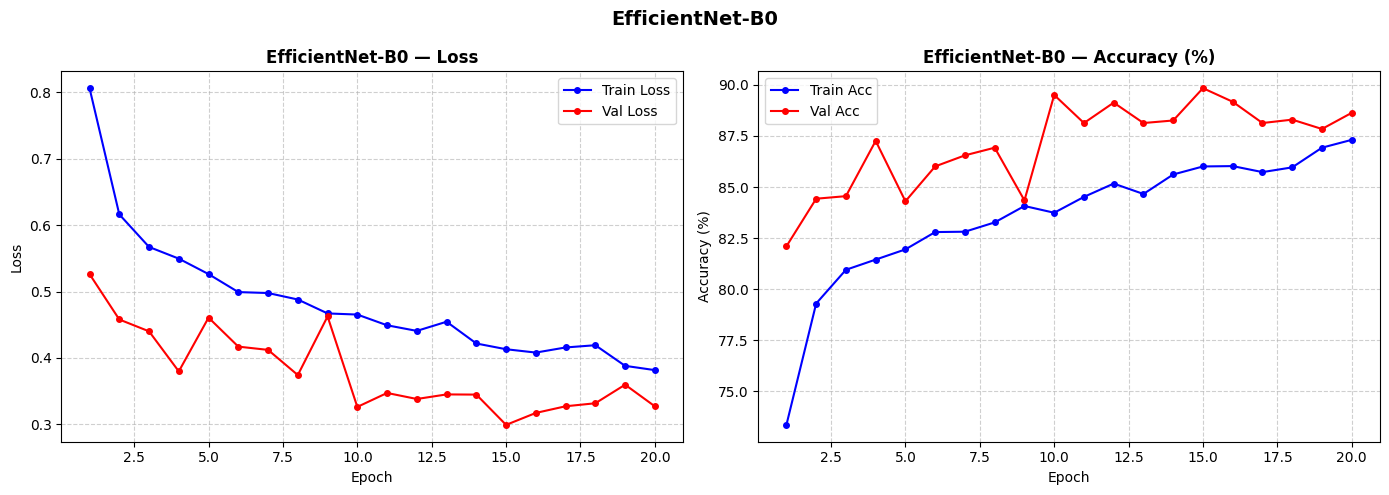

In [23]:
plot_history(eff_history, title='EfficientNet-B0')

### 6.4 Train ResNet50

In [24]:
print("=" * 65)
print("  🟠  Bắt đầu train ResNet50")
print("=" * 65 + "\n")

resnet50 = build_resnet50(num_classes).to(DEVICE)
resnet50, res_history = train_model(resnet50, train_loader, val_loader)

# Lưu model
torch.save(resnet50.state_dict(), "resnet50_tomato.pth")
print("\n💾 Đã lưu model: resnet50_tomato.pth")

  🟠  Bắt đầu train ResNet50

  Epoch [01/30]  Train: Loss=0.8464 Acc=71.76%  |  Val:   Loss=0.4597 Acc=84.51%
  Epoch [02/30]  Train: Loss=0.6681 Acc=76.84%  |  Val:   Loss=0.4132 Acc=85.10%
  Epoch [03/30]  Train: Loss=0.5933 Acc=79.76%  |  Val:   Loss=0.3540 Acc=87.34%
  Epoch [04/30]  Train: Loss=0.5582 Acc=80.87%  |  Val:   Loss=0.4022 Acc=85.76%
  Epoch [05/30]  Train: Loss=0.5341 Acc=81.57%  |  Val:   Loss=0.3392 Acc=88.13%
  Epoch [06/30]  Train: Loss=0.5010 Acc=82.95%  |  Val:   Loss=0.3165 Acc=88.63%
  Epoch [07/30]  Train: Loss=0.5103 Acc=82.56%  |  Val:   Loss=0.2717 Acc=90.97%
  Epoch [08/30]  Train: Loss=0.4979 Acc=83.40%  |  Val:   Loss=0.2917 Acc=89.47%
  Epoch [09/30]  Train: Loss=0.4953 Acc=83.58%  |  Val:   Loss=0.2347 Acc=91.92%
  Epoch [10/30]  Train: Loss=0.4676 Acc=84.08%  |  Val:   Loss=0.2223 Acc=92.05%
  Epoch [11/30]  Train: Loss=0.4760 Acc=83.83%  |  Val:   Loss=0.2332 Acc=92.26%
  Epoch [12/30]  Train: Loss=0.4530 Acc=84.46%  |  Val:   Loss=0.2277 Acc=91.72%

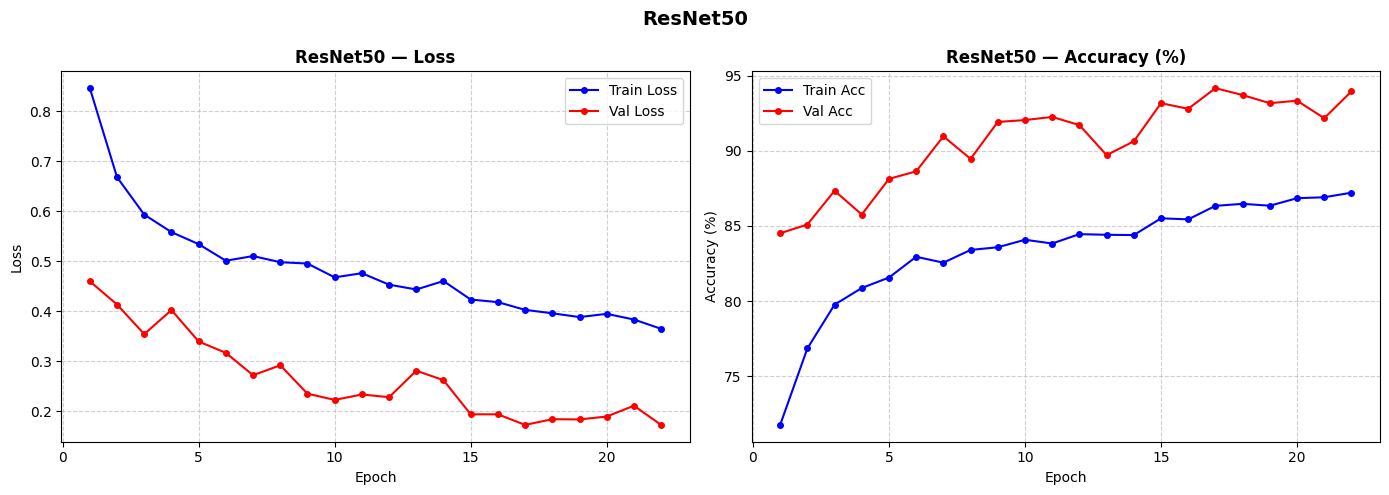

In [25]:
plot_history(res_history, title='ResNet50')

### 6.5 Train Fusion Model (EfficientNet-B0 + ResNet50)

> ⚠️ **Lưu ý**: Fusion model dùng **nhiều VRAM hơn** vì phải chạy 2 backbone cùng lúc.  
> Nếu gặp lỗi OOM (Out of Memory), giảm `BATCH_SIZE` xuống `16`.

In [29]:
print("=" * 65)
print("  🟣  Bắt đầu train Fusion Model (EfficientNet + ResNet50)")
print("=" * 65 + "\n")

fusion_model = FusionModel(num_classes).to(DEVICE)
fusion_model, fusion_history = train_model(fusion_model, train_loader, val_loader)

torch.save(fusion_model.state_dict(), "fusion_tomato.pth")
print("\n💾 Đã lưu model: fusion_tomato.pth")

  🟣  Bắt đầu train Fusion Model (EfficientNet + ResNet50)

  Epoch [01/30]  Train: Loss=0.7368 Acc=75.50%  |  Val:   Loss=0.3655 Acc=88.43%
  Epoch [02/30]  Train: Loss=0.5128 Acc=83.08%  |  Val:   Loss=0.2858 Acc=90.09%
  Epoch [03/30]  Train: Loss=0.4436 Acc=84.93%  |  Val:   Loss=0.2625 Acc=91.01%
  Epoch [04/30]  Train: Loss=0.4150 Acc=85.59%  |  Val:   Loss=0.2215 Acc=92.34%
  Epoch [05/30]  Train: Loss=0.3815 Acc=87.16%  |  Val:   Loss=0.2214 Acc=92.38%
  Epoch [06/30]  Train: Loss=0.3870 Acc=86.75%  |  Val:   Loss=0.2267 Acc=92.17%
  Epoch [07/30]  Train: Loss=0.3606 Acc=87.75%  |  Val:   Loss=0.1829 Acc=94.00%
  Epoch [08/30]  Train: Loss=0.3604 Acc=87.53%  |  Val:   Loss=0.1914 Acc=93.63%
  Epoch [09/30]  Train: Loss=0.3448 Acc=88.09%  |  Val:   Loss=0.1767 Acc=94.21%
  Epoch [10/30]  Train: Loss=0.3411 Acc=88.49%  |  Val:   Loss=0.1817 Acc=93.42%
  Epoch [11/30]  Train: Loss=0.3279 Acc=88.76%  |  Val:   Loss=0.1650 Acc=94.38%
  Epoch [12/30]  Train: Loss=0.3400 Acc=88.33%  | 

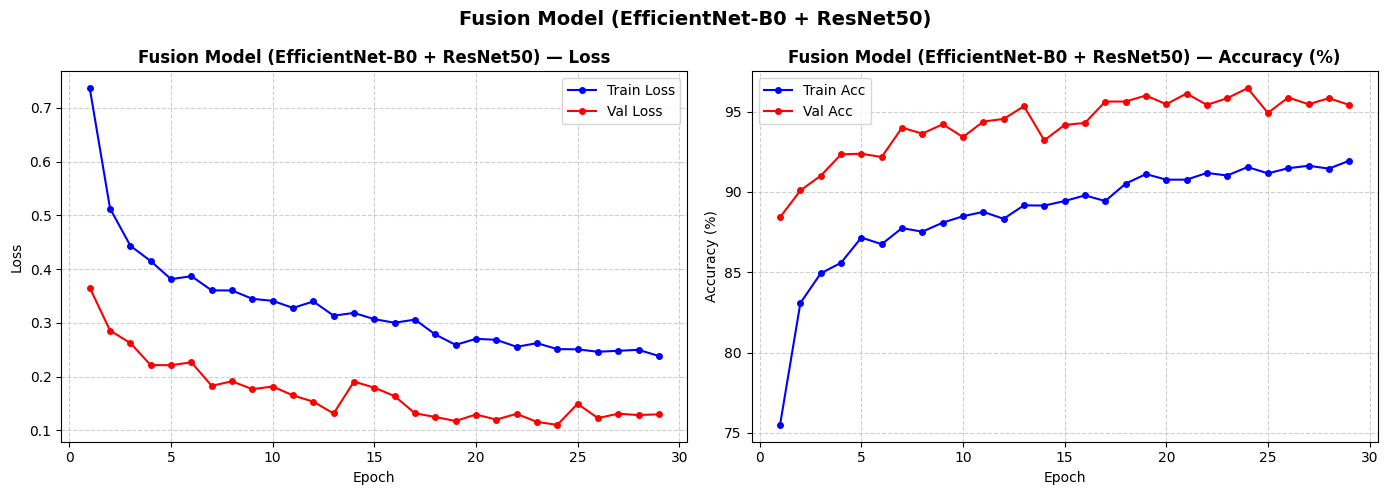

In [30]:
plot_history(fusion_history, title='Fusion Model (EfficientNet-B0 + ResNet50)')

## 7. 📈 Đánh Giá Trên Test Set

### 7.1 Hàm Evaluate

Đánh giá gồm:
- **Test Accuracy** tổng thể
- **Classification Report** — Precision, Recall, F1 từng class
- **Confusion Matrix** — trực quan hóa sai số giữa các class

In [26]:
def evaluate_model(model, test_loader, class_names, title="Model"):
    """Đánh giá model: Accuracy + Classification Report + Confusion Matrix."""
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs        = model(images)
            _, predicted   = outputs.max(1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = sum(p == l for p, l in zip(all_preds, all_labels)) / len(all_labels) * 100
    print(f"\n🎯 {title} — Test Accuracy: {acc:.2f}%\n")

    short_names = [
        c.replace('Tomato__', '').replace('Tomato_', '').replace('_', ' ')
        for c in class_names
    ]
    print("📊 Classification Report:")
    print(classification_report(all_labels, all_preds, target_names=short_names))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=short_names, yticklabels=short_names)
    plt.title(f'Confusion Matrix — {title}', fontsize=14, fontweight='bold')
    plt.xlabel('Predicted', fontsize=12)
    plt.ylabel('Actual', fontsize=12)
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.yticks(rotation=0, fontsize=9)
    plt.tight_layout()
    plt.show()

    return acc, all_preds, all_labels

### 7.2 Đánh Giá EfficientNet-B0

  🔵  Đánh giá EfficientNet-B0 trên Test Set

🎯 EfficientNet-B0 — Test Accuracy: 90.55%

📊 Classification Report:
                                      precision    recall  f1-score   support

                      Bacterial spot       0.94      0.96      0.95       319
                        Early blight       0.77      0.79      0.78       150
                         Late blight       0.85      0.95      0.90       287
                           Leaf Mold       0.92      0.89      0.90       143
                  Septoria leaf spot       0.90      0.83      0.86       265
Spider mites Two spotted spider mite       0.92      0.90      0.91       252
                         Target Spot       0.80      0.84      0.82       210
              YellowLeaf  Curl Virus       0.99      0.98      0.99       482
                        mosaic virus       0.94      0.79      0.85        56
                             healthy       0.93      0.89      0.91       238

                           

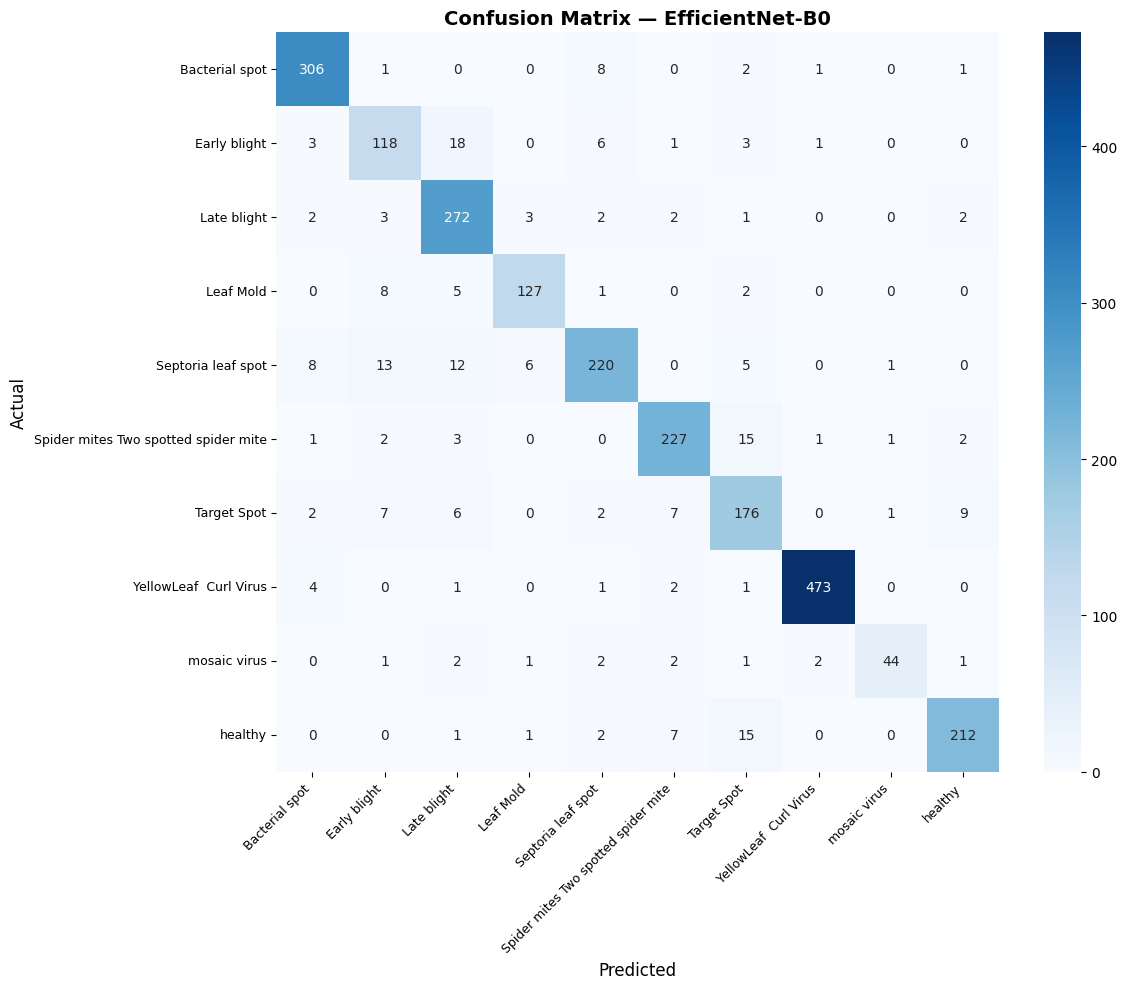

In [27]:
print("=" * 65)
print("  🔵  Đánh giá EfficientNet-B0 trên Test Set")
print("=" * 65)
eff_acc, eff_preds, eff_labels = evaluate_model(
    efficientnet, test_loader, classes, title="EfficientNet-B0"
)

### 7.3 Đánh Giá ResNet50

  🟠  Đánh giá ResNet50 trên Test Set

🎯 ResNet50 — Test Accuracy: 94.50%

📊 Classification Report:
                                      precision    recall  f1-score   support

                      Bacterial spot       0.97      0.98      0.98       319
                        Early blight       0.91      0.86      0.88       150
                         Late blight       0.95      0.97      0.96       287
                           Leaf Mold       1.00      0.83      0.90       143
                  Septoria leaf spot       0.95      0.96      0.95       265
Spider mites Two spotted spider mite       0.94      0.88      0.91       252
                         Target Spot       0.90      0.90      0.90       210
              YellowLeaf  Curl Virus       0.99      0.98      0.99       482
                        mosaic virus       0.84      1.00      0.91        56
                             healthy       0.89      1.00      0.94       238

                            accuracy     

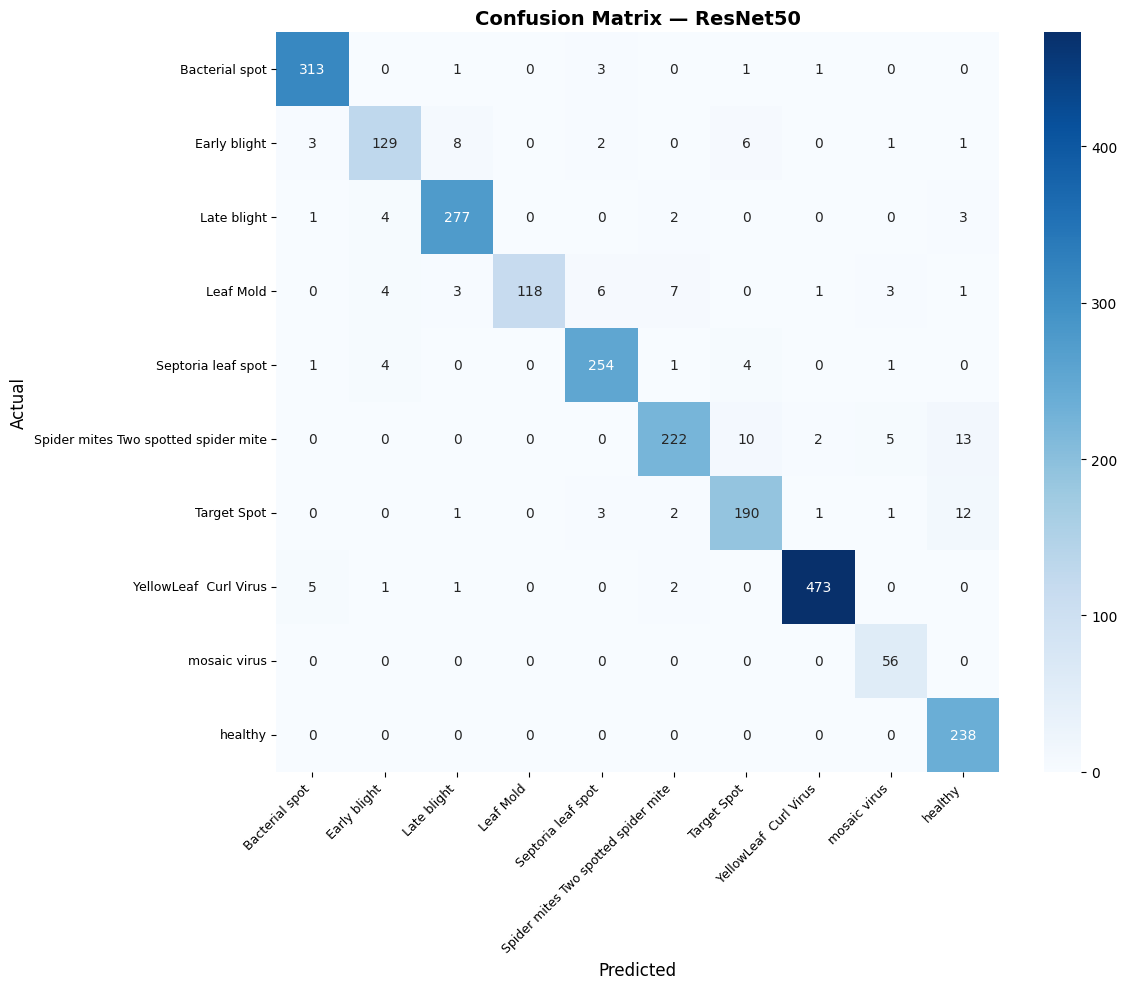

In [28]:
print("=" * 65)
print("  🟠  Đánh giá ResNet50 trên Test Set")
print("=" * 65)
res_acc, res_preds, res_labels = evaluate_model(
    resnet50, test_loader, classes, title="ResNet50"
)

### 7.4 Đánh Giá Fusion Model

  🟣  Đánh giá Fusion Model trên Test Set

🎯 Fusion (EfficientNet + ResNet50) — Test Accuracy: 96.84%

📊 Classification Report:
                                      precision    recall  f1-score   support

                      Bacterial spot       0.98      1.00      0.99       319
                        Early blight       0.94      0.89      0.91       150
                         Late blight       0.95      0.98      0.96       287
                           Leaf Mold       1.00      0.89      0.94       143
                  Septoria leaf spot       0.95      0.98      0.97       265
Spider mites Two spotted spider mite       0.96      0.95      0.96       252
                         Target Spot       0.94      0.97      0.95       210
              YellowLeaf  Curl Virus       1.00      0.98      0.99       482
                        mosaic virus       0.96      0.98      0.97        56
                             healthy       0.98      0.99      0.98       238

             

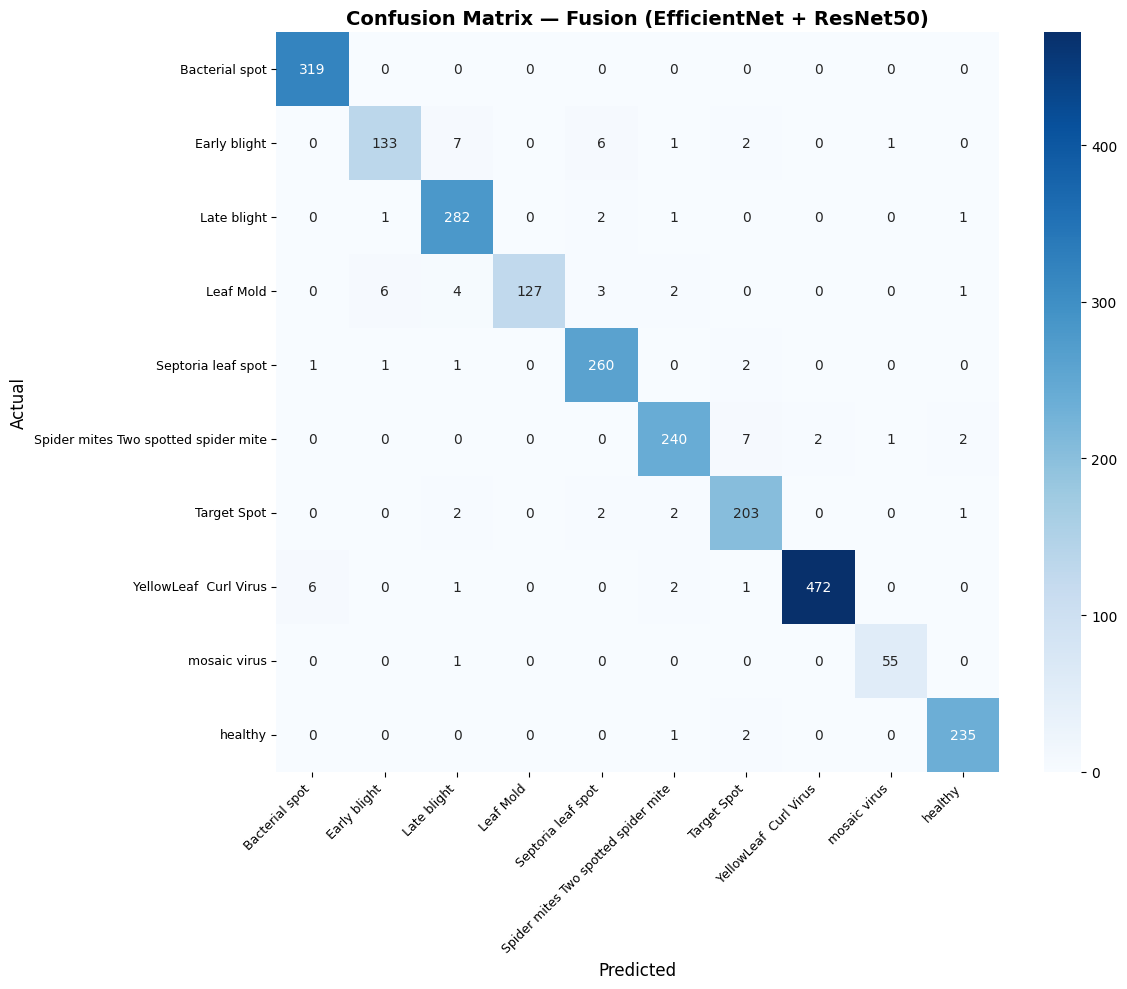

In [31]:
print("=" * 65)
print("  🟣  Đánh giá Fusion Model trên Test Set")
print("=" * 65)
fusion_acc, fusion_preds, fusion_labels = evaluate_model(
    fusion_model, test_loader, classes, title="Fusion (EfficientNet + ResNet50)"
)

## 8. 🏆 So Sánh 3 Model


  📊  KẾT QUẢ CUỐI CÙNG
  EfficientNet-B0                       : 90.55%
  ResNet50                              : 94.50%
  Fusion (EfficientNet + ResNet50)      : 96.84%

🏆 Model tốt nhất: Fusion (EfficientNet + ResNet50)  (96.84%)


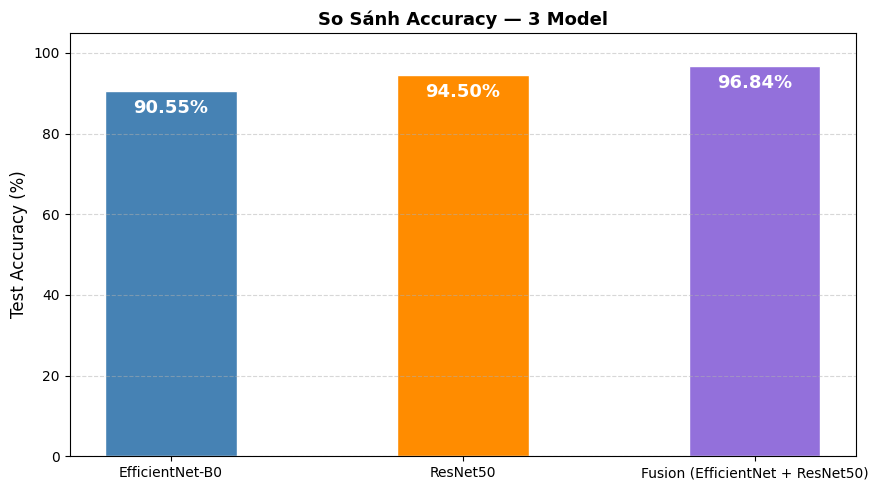

In [32]:
results = {
    "EfficientNet-B0"                 : eff_acc,
    "ResNet50"                        : res_acc,
    "Fusion (EfficientNet + ResNet50)": fusion_acc,
}

print("\n" + "=" * 65)
print("  📊  KẾT QUẢ CUỐI CÙNG")
print("=" * 65)
for name, acc in results.items():
    print(f"  {name:<38s}: {acc:.2f}%")
print("=" * 65)

best_name = max(results, key=results.get)
print(f"\n🏆 Model tốt nhất: {best_name}  ({results[best_name]:.2f}%)")

# ── Bar chart so sánh ─────────────────────────────────────────────
names  = list(results.keys())
accs   = list(results.values())
colors = ['steelblue', 'darkorange', 'mediumpurple']

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(names, accs, color=colors, width=0.45, edgecolor='white')

for bar, acc in zip(bars, accs):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() - 2,
        f'{acc:.2f}%',
        ha='center', va='top',
        color='white', fontsize=13, fontweight='bold'
    )

ax.set_ylim(0, 105)
ax.set_ylabel('Test Accuracy (%)', fontsize=12)
ax.set_title('So Sánh Accuracy — 3 Model', fontsize=13, fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()